# Iris Flower Classification
**Advanced, reproducible supervised-learning workflow**

This notebook classifies Iris flowers as **Setosa**, **Versicolor**, or **Virginica** using four measurements. It combines exploratory data analysis, a stratified hold-out test set, cross-validated model selection, hyperparameter tuning, and final test-set evaluation.

> **Reproducibility:** fixed random seeds are used throughout. The test set is reserved for final evaluation and is not used to choose hyperparameters.

## 1. Imports and configuration

In [5]:
%pip install numpy pandas scikit-learn matplotlib seaborn

  Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl.metadata (61 kB)
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.4 MB 2.4 MB/s eta 0:00:04
   ----- ---------------------------------- 1.0/8.4 MB 2.0 MB/s eta 0:00:04
   ------ --------------------------------- 1.3/8.4 MB 1.9 MB/s eta 0:00:04
   ------ --------------------------------- 1.3/8.4 MB 1.9 MB/s eta 0:00:04
   ------ --------------------------------- 1.3/8.4 MB 1.9 MB/s eta 0:00:04
   ------ --------------------------------- 1.3/8.4 MB 1.9 MB/s eta 0:00:04
   ------ --------------------------------- 1.3/8.4 MB 1.9 MB/s eta 0:00:04
   -------- ------------------------------- 1.8/8.4 MB 986.9 kB/s eta 0:00:07
   ----------- ---------------------------- 2.4/8.4 MB 1.1 MB/s eta 0:00:06
   ------------ --------------------------- 2.6/8.4 MB 1.2 MB/s eta 0:00:05
   ------------ -------------


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import sklearn

print("scikit-learn version:", sklearn.__version__)

from sklearn.datasets import load_iris

iris = load_iris()
print("Dataset loaded successfully!")
print("Number of samples:", len(iris.data))
print("Number of features:", iris.data.shape[1])

scikit-learn version: 1.9.1
Dataset loaded successfully!
Number of samples: 150
Number of features: 4


In [8]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    GridSearchCV
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix
)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
TEST_SIZE = 0.20
CV_SPLITS = 5

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)

## 2. Load data and inspect quality

In [9]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df = df.rename(columns={"target": "target_id"})
df["species"] = df["target_id"].map(dict(enumerate(iris.target_names)))

feature_names = iris.feature_names
target_names = list(iris.target_names)

print(f"Dataset shape: {df.shape}")
display(df.head())

Dataset shape: (150, 6)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target_id,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [10]:
print("Data types:")
display(df.dtypes.to_frame("dtype"))
print("\nMissing values by column:")
display(df.isna().sum().to_frame("missing_count"))
print("\nDuplicate rows:", int(df.duplicated().sum()))
display(df[feature_names].describe().T)
print("\nClass counts:")
display(df["species"].value_counts().rename_axis("species").to_frame("count"))

Data types:


,dtype
sepal length (cm),float64
sepal width (cm),float64
petal length (cm),float64
petal width (cm),float64
target_id,int64
species,str



Missing values by column:


,missing_count
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0
target_id,0
species,0



Duplicate rows: 1


,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5



Class counts:


,count
species,
setosa,50
versicolor,50
virginica,50


**Initial data-quality interpretation:** the built-in scikit-learn Iris dataset contains 150 observations, four numeric measurements, and a three-class target. Check the outputs above rather than assuming data quality. The dataset is a small, curated benchmark; strong scores here do not guarantee performance on new populations or measurement procedures.

## 3. Exploratory data analysis

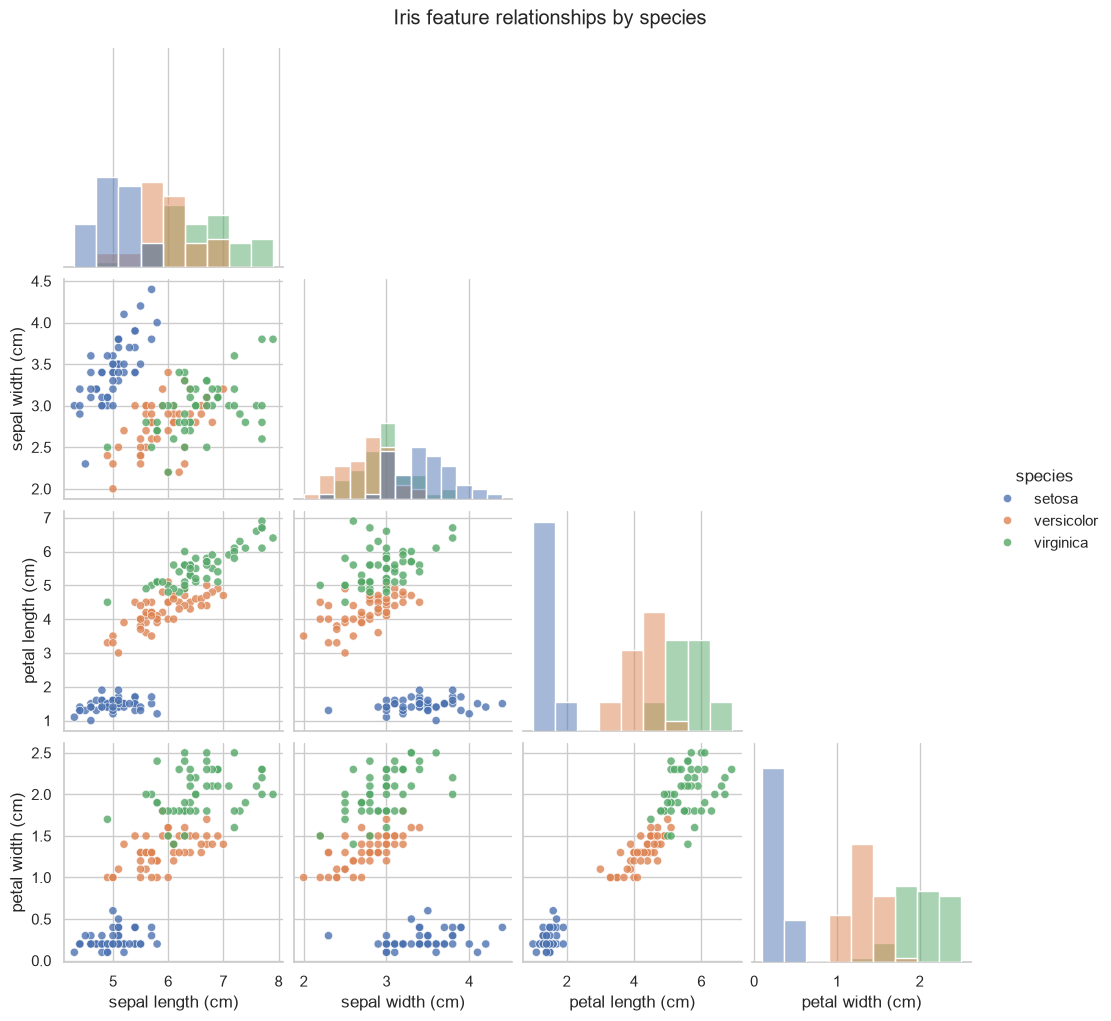

In [11]:
# Pairwise feature relationships, coloured by species.
pairplot = sns.pairplot(
    df, vars=feature_names, hue="species", corner=True,
    diag_kind="hist", plot_kws={"alpha": 0.8, "s": 35}
)
pairplot.fig.suptitle("Iris feature relationships by species", y=1.02)
plt.show()

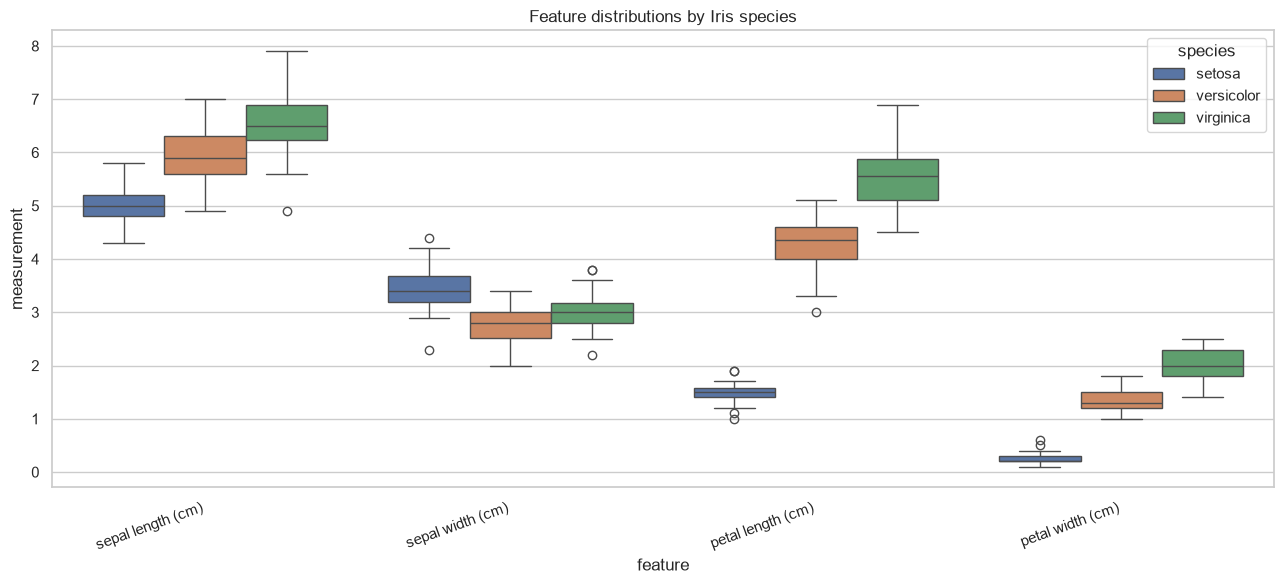

In [12]:
# Box plots show class-wise distributions and potential overlap/outliers.
long_df = df.melt(
    id_vars="species", value_vars=feature_names,
    var_name="feature", value_name="measurement"
)
plt.figure(figsize=(13, 6))
sns.boxplot(data=long_df, x="feature", y="measurement", hue="species")
plt.title("Feature distributions by Iris species")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

In [13]:
# Class-wise means and standard deviations support the visual inspection.
display(df.groupby("species")[feature_names].agg(["mean", "std"]).round(3))

sepal length (cm)        sepal width (cm)        petal length (cm)  \
                        mean    std             mean    std              mean   
species                                                                         
setosa                 5.006  0.352            3.428  0.379             1.462   
versicolor             5.936  0.516            2.770  0.314             4.260   
virginica              6.588  0.636            2.974  0.322             5.552   

                  petal width (cm)         
              std             mean    std  
species                                    
setosa      0.174            0.246  0.105  
versicolor  0.470            1.326  0.198  
virginica   0.552            2.026  0.275

### Feature-selection discussion

Use the pairplot and boxplots to assess separation, not just feature scale. Petal length and petal width usually separate Setosa very clearly and help distinguish Versicolor from Virginica, while sepal measurements overlap more. This is a dataset-level observation, not a guarantee for every observation. The modelling section uses all four features initially, then permutation importance provides a model-specific check. Feature importance is predictive association, not causal explanation.

## 4. Train/test split

In [14]:
X = df[feature_names].copy()
y = df["target_id"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)
print("\nTraining class proportions:")
display(y_train.map(dict(enumerate(target_names))).value_counts(normalize=True).sort_index().round(3))

Training shape: (120, 4)
Test shape: (30, 4)

Training class proportions:


target_id
setosa        0.333
versicolor    0.333
virginica     0.333
Name: proportion, dtype: float64

## 5. Baseline models with cross-validation

Scaling is important for Logistic Regression and KNN, so preprocessing is kept inside a pipeline. This prevents scaling statistics from leaking across cross-validation folds. Random Forest does not require feature scaling, but using a pipeline keeps the workflow consistent.

In [15]:
cv = StratifiedKFold(n_splits=CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)

baseline_models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE))
    ]),
    "K-Nearest Neighbours": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier())
    ]),
    "Decision Tree": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DecisionTreeClassifier(random_state=RANDOM_STATE))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(random_state=RANDOM_STATE))
    ])
}

scoring = {"accuracy": "accuracy", "f1_macro": "f1_macro"}
baseline_rows = []
for name, model in baseline_models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    baseline_rows.append({
        "model": name,
        "cv_accuracy_mean": scores["test_accuracy"].mean(),
        "cv_accuracy_std": scores["test_accuracy"].std(),
        "cv_macro_f1_mean": scores["test_f1_macro"].mean()
    })

baseline_results = pd.DataFrame(baseline_rows).sort_values(
    "cv_macro_f1_mean", ascending=False
).reset_index(drop=True)
display(baseline_results.round(4))

,model,cv_accuracy_mean,cv_accuracy_std,cv_macro_f1_mean
0,Logistic Regression,0.9583,0.0264,0.9580
1,K-Nearest Neighbours,0.9583,0.0264,0.9580
2,Decision Tree,0.9500,0.0167,0.9496
3,Random Forest,0.9500,0.0312,0.9494


## 6. Hyperparameter tuning with GridSearchCV

In [16]:
param_grids = {
    "Logistic Regression": (
        baseline_models["Logistic Regression"],
        {
            "model__C": [0.01, 0.1, 1, 10, 100],
            "model__solver": ["lbfgs"],
            "model__class_weight": [None, "balanced"]
        }
    ),
    "K-Nearest Neighbours": (
        baseline_models["K-Nearest Neighbours"],
        {
            "model__n_neighbors": [3, 5, 7, 9, 11, 13],
            "model__weights": ["uniform", "distance"],
            "model__p": [1, 2]
        }
    ),
    "Decision Tree": (
        baseline_models["Decision Tree"],
        {
            "model__max_depth": [None, 2, 3, 4, 5],
            "model__min_samples_leaf": [1, 2, 4],
            "model__criterion": ["gini", "entropy"]
        }
    ),
    "Random Forest": (
        baseline_models["Random Forest"],
        {
            "model__n_estimators": [100, 200, 400],
            "model__max_depth": [None, 3, 5, 8],
            "model__min_samples_leaf": [1, 2, 4],
            "model__max_features": ["sqrt", None]
        }
    )
}

searches = {}
tuning_rows = []
for name, (estimator, grid) in param_grids.items():
    search = GridSearchCV(
        estimator=estimator, param_grid=grid, scoring="f1_macro",
        cv=cv, n_jobs=-1, refit=True, return_train_score=True
    )
    search.fit(X_train, y_train)
    searches[name] = search
    tuning_rows.append({
        "model": name,
        "best_cv_macro_f1": search.best_score_,
        "best_parameters": search.best_params_
    })

tuning_results = pd.DataFrame(tuning_rows).sort_values(
    "best_cv_macro_f1", ascending=False
).reset_index(drop=True)
display(tuning_results)

,model,best_cv_macro_f1,best_parameters
0,K-Nearest Neighbours,0.966536,"{'model__n_neighbors': 3, 'model__p': 2, 'mode..."
1,Logistic Regression,0.966337,"{'model__C': 10, 'model__class_weight': None, ..."
2,Random Forest,0.966337,"{'model__max_depth': None, 'model__max_feature..."
3,Decision Tree,0.957971,"{'model__criterion': 'gini', 'model__max_depth..."


## 7. Final evaluation on the untouched test set

The model is selected using mean cross-validated macro F1 on the training split. Macro F1 gives each class equal weight. Only after selection do we evaluate the chosen estimator on the held-out test data. Because Iris is small, tiny score differences can be unstable; report the observed results without overclaiming.

In [17]:
best_name = tuning_results.loc[0, "model"]
best_model = searches[best_name].best_estimator_
print("Selected model by training CV macro-F1:", best_name)
print("Best CV macro-F1:", round(searches[best_name].best_score_, 4))

test_predictions = best_model.predict(X_test)
test_metrics = {
    "model": best_name,
    "test_accuracy": accuracy_score(y_test, test_predictions),
    "test_precision_macro": precision_score(y_test, test_predictions, average="macro", zero_division=0),
    "test_recall_macro": recall_score(y_test, test_predictions, average="macro", zero_division=0),
    "test_f1_macro": f1_score(y_test, test_predictions, average="macro", zero_division=0)
}
display(pd.DataFrame([test_metrics]).round(4))
print(classification_report(
    y_test, test_predictions, target_names=target_names, zero_division=0
))

Selected model by training CV macro-F1: K-Nearest Neighbours
Best CV macro-F1: 0.9665


,model,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro
0,K-Nearest Neighbours,0.9333,0.9444,0.9333,0.9327


              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



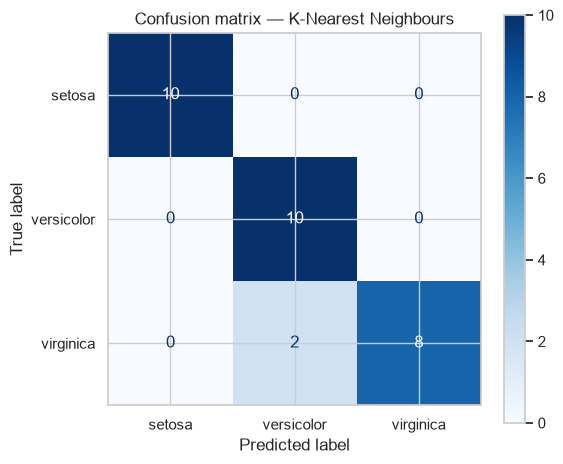

In [18]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, test_predictions, display_labels=target_names,
    cmap="Blues", values_format="d", ax=ax
)
ax.set_title(f"Confusion matrix — {best_name}")
plt.tight_layout()
plt.show()

## 8. Compare tuned models on the held-out test set

,model,best_cv_macro_f1,test_accuracy,test_precision_macro,test_recall_macro,test_f1_macro
1,K-Nearest Neighbours,0.9665,0.9333,0.9444,0.9333,0.9327
0,Logistic Regression,0.9663,1.0000,1.0000,1.0000,1.0000
3,Random Forest,0.9663,0.9667,0.9697,0.9667,0.9666
2,Decision Tree,0.9580,0.9333,0.9333,0.9333,0.9333


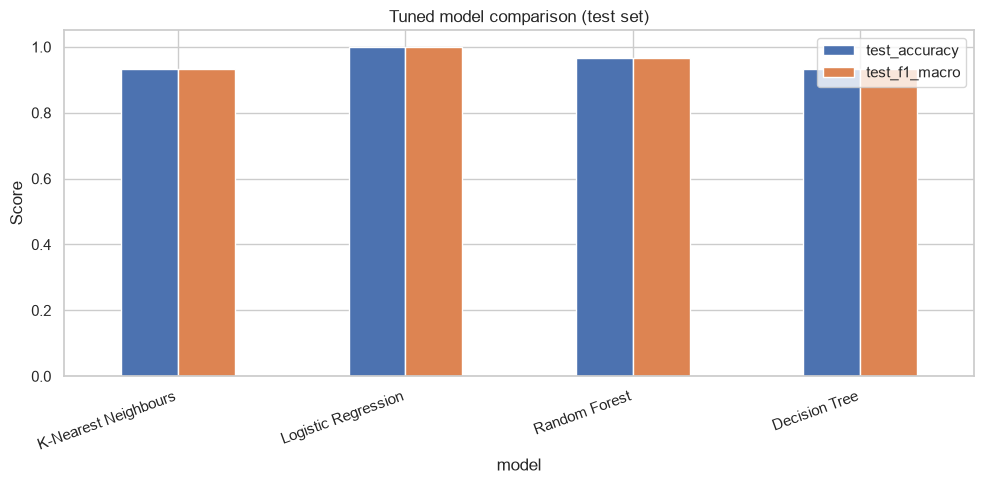

In [19]:
comparison_rows = []
for name, search in searches.items():
    pred = search.best_estimator_.predict(X_test)
    comparison_rows.append({
        "model": name,
        "best_cv_macro_f1": search.best_score_,
        "test_accuracy": accuracy_score(y_test, pred),
        "test_precision_macro": precision_score(y_test, pred, average="macro", zero_division=0),
        "test_recall_macro": recall_score(y_test, pred, average="macro", zero_division=0),
        "test_f1_macro": f1_score(y_test, pred, average="macro", zero_division=0)
    })
comparison = pd.DataFrame(comparison_rows).sort_values("best_cv_macro_f1", ascending=False)
display(comparison.round(4))
ax = comparison.set_index("model")[["test_accuracy", "test_f1_macro"]].plot(
    kind="bar", figsize=(10, 5), ylim=(0, 1.05)
)
ax.set_ylabel("Score")
ax.set_title("Tuned model comparison (test set)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 9. Permutation importance

,feature,importance_mean,importance_std
3,petal width (cm),0.2627,0.0705
2,petal length (cm),0.2198,0.0863
1,sepal width (cm),0.0192,0.0446
0,sepal length (cm),0.0044,0.0273


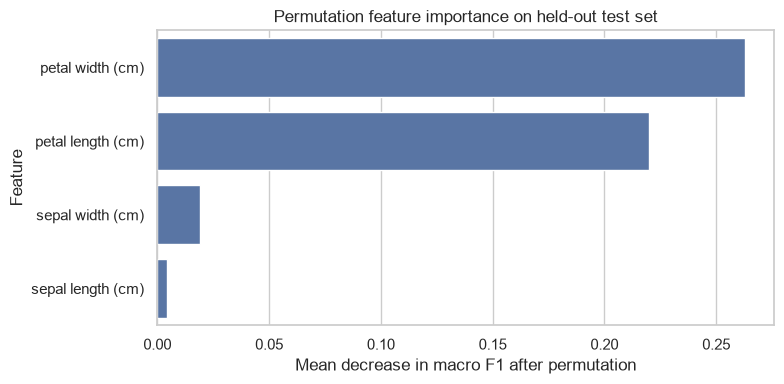

In [20]:
# Permutation importance measures the drop in score when a feature is shuffled.
perm = permutation_importance(
    best_model, X_test, y_test, scoring="f1_macro",
    n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1
)
importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)
display(importance_df.round(4))

plt.figure(figsize=(8, 4))
sns.barplot(data=importance_df, x="importance_mean", y="feature")
plt.xlabel("Mean decrease in macro F1 after permutation")
plt.ylabel("Feature")
plt.title("Permutation feature importance on held-out test set")
plt.tight_layout()
plt.show()